In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")


In [3]:
df = pd.read_excel('heart_disease.xlsx')

In [4]:
df.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,45,M,ATA,130,233,Normal,150,N,0.0,Up,0
1,54,F,NAP,120,261,Normal,140,N,0.3,Up,0
2,62,M,ASY,140,289,LVH,120,Y,2.0,Flat,1
3,38,F,ATA,110,198,Normal,170,N,0.0,Up,0
4,57,M,NAP,128,245,Normal,155,N,1.0,Flat,0


EDA

In [5]:
df.columns

Index(['Age', 'Sex', 'ChestPainType', 'RestingBP', 'Cholesterol', 'RestingECG',
       'MaxHR', 'ExerciseAngina', 'Oldpeak', 'ST_Slope', 'HeartDisease'],
      dtype='object')

In [6]:
df.shape

(60, 11)

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 60 entries, 0 to 59
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             60 non-null     int64  
 1   Sex             60 non-null     object 
 2   ChestPainType   60 non-null     object 
 3   RestingBP       60 non-null     int64  
 4   Cholesterol     60 non-null     int64  
 5   RestingECG      60 non-null     object 
 6   MaxHR           60 non-null     int64  
 7   ExerciseAngina  60 non-null     object 
 8   Oldpeak         60 non-null     float64
 9   ST_Slope        60 non-null     object 
 10  HeartDisease    60 non-null     int64  
dtypes: float64(1), int64(5), object(5)
memory usage: 5.3+ KB


In [8]:
df.describe()

,Age,RestingBP,Cholesterol,MaxHR,Oldpeak,HeartDisease
count,60.000000,60.000000,60.000000,60.000000,60.000000,60.000000
mean,53.700000,132.866667,252.600000,138.483333,1.176667,0.416667
std,10.238346,15.353978,38.824769,24.299328,1.136209,0.497167
min,34.000000,105.000000,185.000000,100.000000,0.000000,0.000000
25%,45.750000,121.750000,219.750000,115.750000,0.175000,0.000000
50%,54.500000,130.000000,248.500000,141.000000,0.650000,0.000000
75%,62.000000,146.000000,285.500000,160.250000,2.325000,1.000000
max,72.000000,165.000000,325.000000,180.000000,3.200000,1.000000


In [9]:
df.duplicated().sum()

np.int64(0)

<Axes: title={'center': 'Heart Disease Distribution'}, xlabel='HeartDisease'>

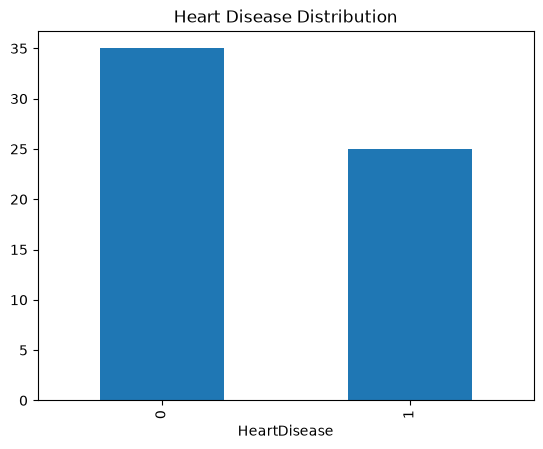

In [10]:
df["HeartDisease"].value_counts().plot(kind="bar", title="Heart Disease Distribution")

In [11]:
df.isnull().sum()

Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64

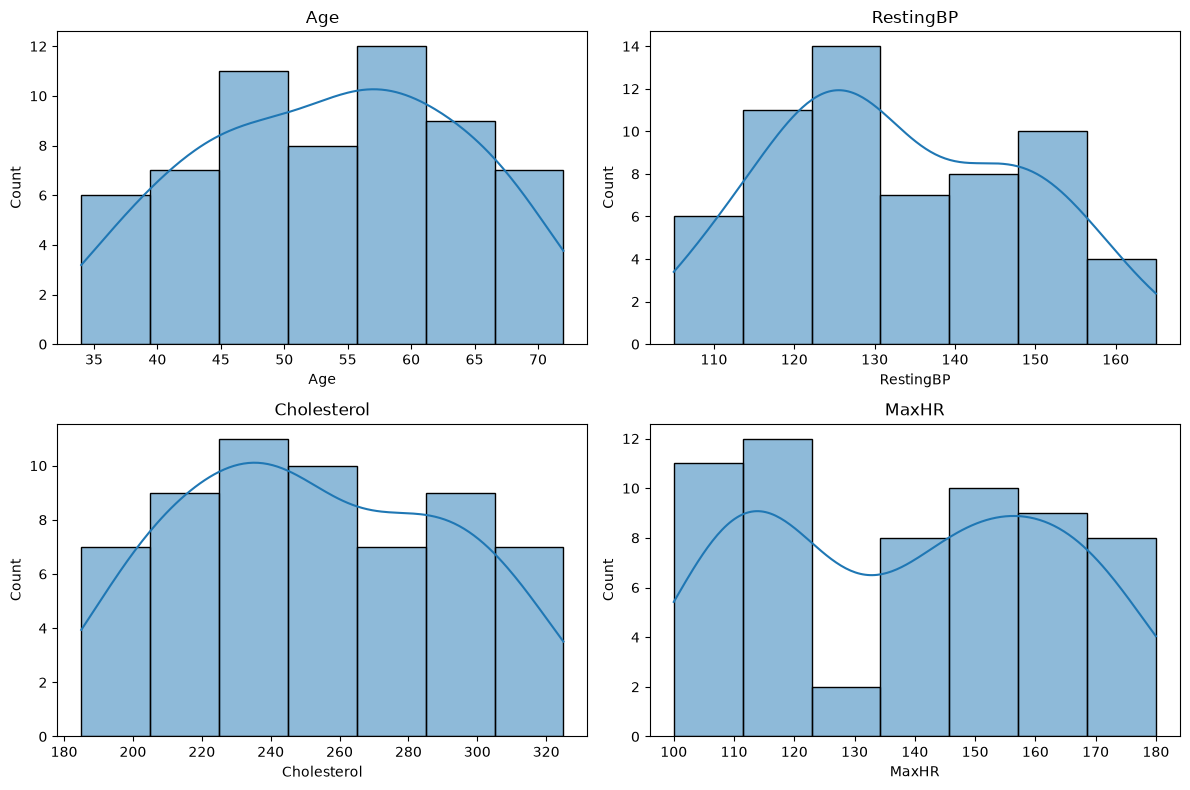

In [15]:
def plotting(var, ax):
    sns.histplot(df[var], kde=True, ax=ax)
    ax.set_title(var)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

plotting("Age", axes[0, 0])
plotting("RestingBP", axes[0, 1])
plotting("Cholesterol", axes[1, 0])
plotting("MaxHR", axes[1, 1])

plt.tight_layout()
plt.show()


In [16]:
df["Cholesterol"].value_counts()

Cholesterol
235    2
261    1
233    1
198    1
245    1
310    1
220    1
270    1
215    1
280    1
289    1
240    1
255    1
190    1
300    1
230    1
205    1
325    1
275    1
218    1
260    1
295    1
225    1
248    1
200    1
285    1
315    1
212    1
250    1
290    1
238    1
302    1
210    1
252    1
318    1
185    1
278    1
228    1
292    1
202    1
246    1
287    1
216    1
268    1
242    1
195    1
305    1
263    1
208    1
298    1
232    1
276    1
188    1
249    1
321    1
219    1
284    1
236    1
309    1
Name: count, dtype: int64

In [17]:
print("Total missing values:", df.isnull().sum().sum())

Total missing values: 0


In [18]:
print(df.describe())

             Age   RestingBP  Cholesterol       MaxHR    Oldpeak  HeartDisease
count  60.000000   60.000000    60.000000   60.000000  60.000000     60.000000
mean   53.700000  132.866667   252.600000  138.483333   1.176667      0.416667
std    10.238346   15.353978    38.824769   24.299328   1.136209      0.497167
min    34.000000  105.000000   185.000000  100.000000   0.000000      0.000000
25%    45.750000  121.750000   219.750000  115.750000   0.175000      0.000000
50%    54.500000  130.000000   248.500000  141.000000   0.650000      0.000000
75%    62.000000  146.000000   285.500000  160.250000   2.325000      1.000000
max    72.000000  165.000000   325.000000  180.000000   3.200000      1.000000


In [19]:
cols = ["Age", "RestingBP", "Cholesterol", "MaxHR", "Oldpeak"]

for col in cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower) | (df[col] > upper)]

    print(f"{col}: {len(outliers)} outliers")

Age: 0 outliers
RestingBP: 0 outliers
Cholesterol: 0 outliers
MaxHR: 0 outliers
Oldpeak: 0 outliers


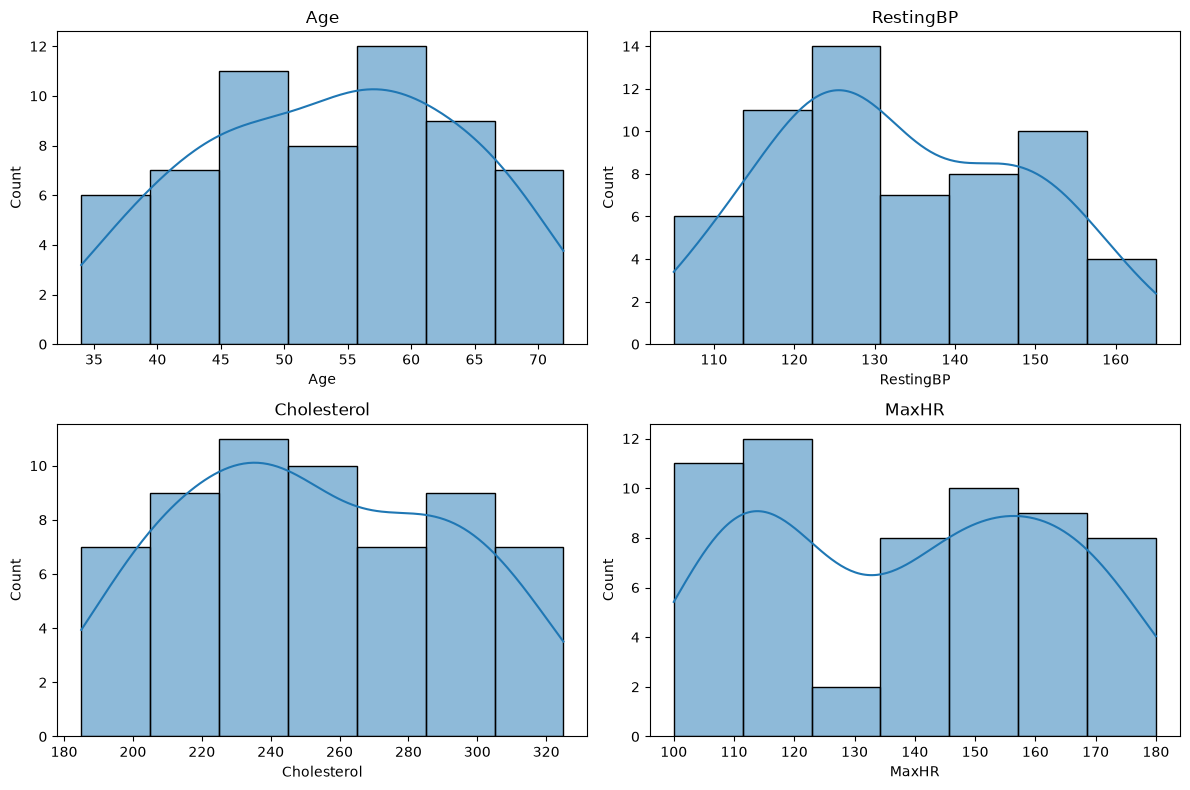

In [20]:
def plotting(var, ax):
    sns.histplot(df[var], kde=True, ax=ax)
    ax.set_title(var)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

plotting("Age", axes[0, 0])
plotting("RestingBP", axes[0, 1])
plotting("Cholesterol", axes[1, 0])
plotting("MaxHR", axes[1, 1])

plt.tight_layout()
plt.show()


<Axes: xlabel='Sex', ylabel='count'>

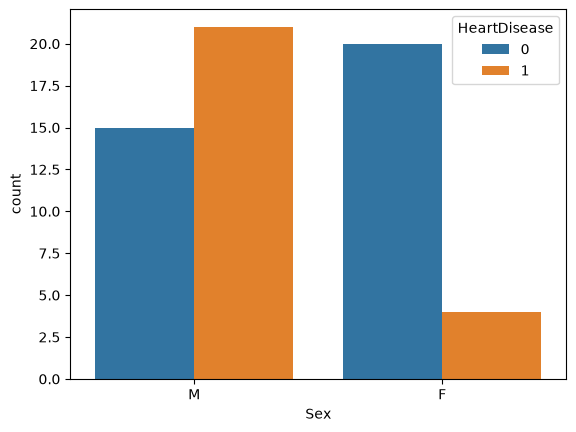

In [28]:
sns.countplot(x=df["Sex"], hue= df["HeartDisease"])

<Axes: xlabel='ChestPainType', ylabel='count'>

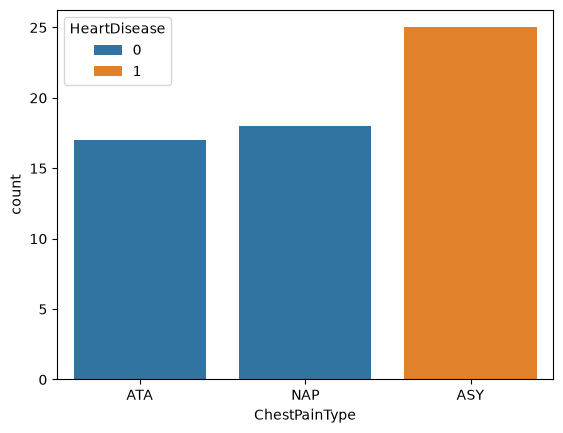

In [27]:
sns.countplot(x=df["ChestPainType"], hue=df["HeartDisease"])

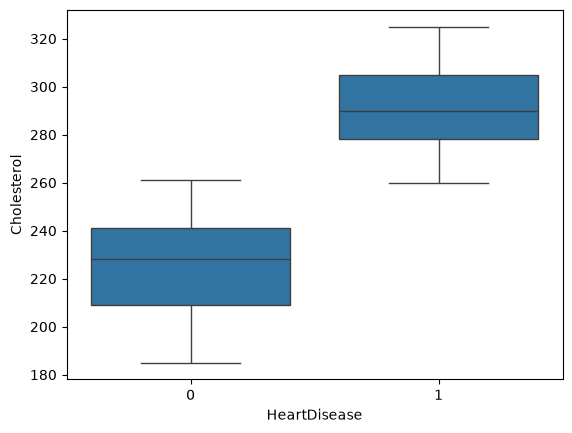

In [36]:
sns.boxplot(x="HeartDisease", y ="Cholesterol",data= df)
plt.show()

<Axes: xlabel='HeartDisease', ylabel='Age'>

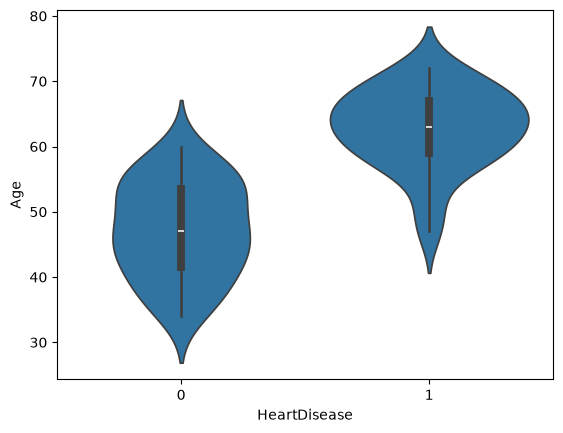

In [37]:
sns.violinplot(x="HeartDisease", y="Age", data =df)

<Axes: >

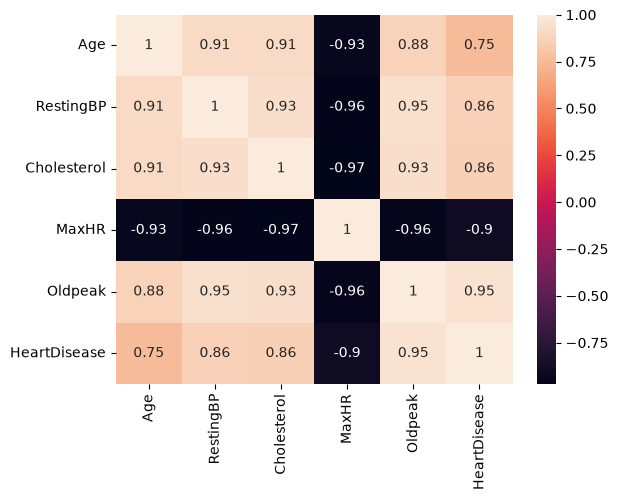

In [38]:
sns.heatmap(df.corr(numeric_only=True), annot=True)

DATA PROCESSING AND CLEANING

In [39]:
df_encode=pd.get_dummies(df, drop_first=True)

In [40]:
df_encode

,Age,RestingBP,Cholesterol,MaxHR,Oldpeak,HeartDisease,Sex_M,ChestPainType_ATA,ChestPainType_NAP,RestingECG_Normal,RestingECG_ST,ExerciseAngina_Y,ST_Slope_Flat,ST_Slope_Up
0,45,130,233,150,0.0,0,True,True,False,True,False,False,False,True
1,54,120,261,140,0.3,0,False,False,True,True,False,False,False,True
2,62,140,289,120,2.0,1,True,False,False,False,False,True,True,False
3,38,110,198,170,0.0,0,False,True,False,True,False,False,False,True
4,57,128,245,155,1.0,0,True,False,True,True,False,False,True,False
5,66,150,310,110,2.5,1,True,False,False,False,True,True,False,False
6,49,125,220,160,0.2,0,False,True,False,True,False,False,False,True
7,59,135,270,125,1.8,1,True,False,False,False,True,True,True,False
8,43,122,215,165,0.0,0,True,False,True,True,False,False,False,True
9,71,160,280,105,3.0,1,False,False,False,False,False,True,False,False


In [42]:
df_encode= df_encode.astype(int)

In [43]:
df_encode

,Age,RestingBP,Cholesterol,MaxHR,Oldpeak,HeartDisease,Sex_M,ChestPainType_ATA,ChestPainType_NAP,RestingECG_Normal,RestingECG_ST,ExerciseAngina_Y,ST_Slope_Flat,ST_Slope_Up
0,45,130,233,150,0,0,1,1,0,1,0,0,0,1
1,54,120,261,140,0,0,0,0,1,1,0,0,0,1
2,62,140,289,120,2,1,1,0,0,0,0,1,1,0
3,38,110,198,170,0,0,0,1,0,1,0,0,0,1
4,57,128,245,155,1,0,1,0,1,1,0,0,1,0
5,66,150,310,110,2,1,1,0,0,0,1,1,0,0
6,49,125,220,160,0,0,0,1,0,1,0,0,0,1
7,59,135,270,125,1,1,1,0,0,0,1,1,1,0
8,43,122,215,165,0,0,1,0,1,1,0,0,0,1
9,71,160,280,105,3,1,0,0,0,0,0,1,0,0


In [44]:
from sklearn.preprocessing import StandardScaler

In [46]:
numerical_cols =['Age','RestingBP','Cholesterol', 'MaxHR', 'Oldpeak']
scaler = StandardScaler()
df_encode[numerical_cols]= scaler.fit_transform(df_encode[numerical_cols])
df_encode.head()

,Age,RestingBP,Cholesterol,MaxHR,Oldpeak,HeartDisease,Sex_M,ChestPainType_ATA,ChestPainType_NAP,RestingECG_Normal,RestingECG_ST,ExerciseAngina_Y,ST_Slope_Flat,ST_Slope_Up
0,-0.856918,-0.188281,-0.509093,0.477950,-0.812601,0,1,1,0,1,0,0,0,1
1,0.029549,-0.845074,0.218183,0.062943,-0.812601,0,0,0,1,1,0,0,0,1
2,0.817519,0.468513,0.945458,-0.767071,1.099401,1,1,0,0,0,0,1,1,0
3,-1.546392,-1.501867,-1.418187,1.307964,-0.812601,0,0,1,0,1,0,0,0,1
4,0.325038,-0.319639,-0.197403,0.685453,0.143400,0,1,0,1,1,0,0,1,0
